# Operando Pipeline Runner

Fill in the paths below, then run all cells.

This notebook loads `operando data.py` and `operando plots.py` relative to the `toolbox/operando` folder so it works regardless of where `toolbox` lives.

In [12]:
# Imports
import os
import importlib.util

# Resolve module paths relative to this notebook location
# Assumes this notebook lives in toolbox/operando
notebook_dir = os.path.abspath(os.getcwd())
data_module_path = os.path.join(notebook_dir, "operando data.py")
plots_module_path = os.path.join(notebook_dir, "operando plots.py")

# Load operando data module
data_spec = importlib.util.spec_from_file_location("operando_data", data_module_path)
operando_data = importlib.util.module_from_spec(data_spec)
data_spec.loader.exec_module(operando_data)

# Load operando plots module
plots_spec = importlib.util.spec_from_file_location("operando_plots", plots_module_path)
operando_plots = importlib.util.module_from_spec(plots_spec)
plots_spec.loader.exec_module(operando_plots)

run_operando_pipeline = operando_data.run_operando_pipeline


In [13]:
# === Base directory ===
# Set this to the root folder that contains your data_raw folder
base_dir = r"/data01/Leon_BOA_December2025"

# === Paths under base_dir ===
exp_dir = os.path.join(base_dir, "LiMetal/exp1301_LiMetal_final")
beamhistory_path = os.path.join(base_dir, "LiMetal/Leon_BOA_Dec2025_exp1301_LiMetal_final_1s.csv")

reference_dir = os.path.join(base_dir, "Ref/exp004_Ref1um_NewCell_40x20NA_wmetal")
reference_beamhistory_path = os.path.join(base_dir, "Ref/Leon_BOA_Dec2025_Ref.csv")
reference_bin_y = 2
reference_bin_x = 2
reference_final_subfolder = "final"


echem_folder = os.path.join(base_dir, "EChem_Dec 02-09 2025 (BOA)/6Lithium Metal")
video_output_path = os.path.join(base_dir, "LiMetal/exp1301_LiMetal_final.mp4")

# Optional
output_dir = None  # auto-name with experiment folder
exposure_seconds = 2
uncorrected_output_folder_name = None  # auto-name with experiment folder



In [14]:
# Run pipeline
result = run_operando_pipeline(
    exp_dir=exp_dir,
    beamhistory_path=beamhistory_path,
    output_dir=output_dir,
    exposure_seconds=exposure_seconds,
    reference_dir=reference_dir,
    reference_beamhistory_path=reference_beamhistory_path,
    uncorrected_output_folder_name=uncorrected_output_folder_name,
    reference_bin_y=reference_bin_y,
    reference_bin_x=reference_bin_x,
    reference_final_subfolder=reference_final_subfolder,
)

result


/data01/data_acquisition/scripts/toolbox/operando/operando data.py:638: UserWarning: Skipped 1 existing corrected files in run exp1301_LiMetal_final_00000.
  warnings.warn(
/data01/data_acquisition/scripts/toolbox/operando/operando data.py:638: UserWarning: Skipped 1 existing corrected files in run exp1301_LiMetal_final_00001.
  warnings.warn(
/data01/data_acquisition/scripts/toolbox/operando/operando data.py:638: UserWarning: Skipped 1 existing corrected files in run exp1301_LiMetal_final_00002.
  warnings.warn(
/data01/data_acquisition/scripts/toolbox/operando/operando data.py:638: UserWarning: Skipped 1 existing corrected files in run exp1301_LiMetal_final_00003.
  warnings.warn(
/data01/data_acquisition/scripts/toolbox/operando/operando data.py:638: UserWarning: Skipped 1 existing corrected files in run exp1301_LiMetal_final_00004.
  warnings.warn(
/data01/data_acquisition/scripts/toolbox/operando/operando data.py:638: UserWarning: Skipped 1 existing corrected files in run exp1301_

{'corrected_dir': '/data01/Leon_BOA_December2025/LiMetal/obint_corrected_exp1301_LiMetal_final',
 'uncorrected_dir': '/data01/Leon_BOA_December2025/LiMetal/uncorrected_exp1301_LiMetal_final',
 'reference_beam_integral_per_minute': 83389.54284559663}

## Background Subtraction (Post-ImageJ)
 This section subtracts a background TIFF from the corrected images and writes intermediate and final outputs.


In [15]:
from pathlib import Path
import numpy as np
import tifffile

# === Fill these in ===
# Path to background TIFF to subtract
background_path = os.path.join(base_dir, "LiMetal/spotfix_exp1301_LiMetal_final.tif")

# Input corrected folder (from pipeline)
corrected_dir = Path(result["corrected_dir"])

# Final output folder (sibling to corrected_dir)
exp_name = corrected_dir.name.replace("obint_corrected_", "")
final_dir = corrected_dir.parent / ("final_" + exp_name)
final_dir.mkdir(parents=True, exist_ok=True)

# Load background image
bg = tifffile.imread(background_path).astype(np.float32)

def read_custom_tags(path):
    try:
        with tifffile.TiffFile(path) as tif:
            tags = tif.pages[0].tags
            out = {}
            for code in (65000, 65001, 65002):
                if code in tags:
                    out[code] = tags[code].value
            return out
    except Exception:
        return {}

for p in sorted(corrected_dir.iterdir()):
    if not p.is_file():
        continue
    try:
        img = tifffile.imread(str(p)).astype(np.float32)
    except Exception:
        continue

    if img.shape != bg.shape:
        raise ValueError(f"Background shape {bg.shape} does not match image {p.name} shape {img.shape}")

    bgsub = img - bg

    # Optional: clip negatives
    bgsub = np.maximum(bgsub, 0)

    tags = read_custom_tags(str(p))
    extratags = []
    if 65001 in tags:
        extratags.append((65001, "d", 1, float(tags[65001]), False))
    if 65000 in tags:
        extratags.append((65000, "s", 0, tags[65000], False))
    if 65002 in tags:
        extratags.append((65002, "s", 0, tags[65002], False))

    final_path = final_dir / p.name
    tifffile.imwrite(str(final_path), bgsub.astype(np.float32), extratags=extratags)

print("Wrote:", final_dir)

Wrote: /data01/Leon_BOA_December2025/LiMetal/final_exp1301_LiMetal_final


### The images should have been OB-corrected with the reference image. Before plotting, you may need to manually filter bright spots from TPX hot pixels.

# Plotting and Video

This section loads corrected images, extracts `MeanTPXModifiedTime` from TIFF tags, loads electrochemical data, then creates:
- A potential + image video
- A potential + thickness plot

In [16]:
# Plot/video settings
conv_thickness = 1.0
time_column = "time/s"
fps = 10
dt_seconds = 120
cmap = "inferno"
vmin = 0
vmax = 3
dpi = 150
merge_minutes = 1
merge_method = "mean"
roi = dict(r0=160, x0=224, y0=219)
potential_ylim=(-0.4, 0.6)

In [17]:
import tifffile
from datetime import datetime

def load_corrected_images_with_time(corrected_dir, tag_id=65002, r0=None, x0=None, y0=None):
    records = []
    for fname in sorted(os.listdir(corrected_dir)):
        path = os.path.join(corrected_dir, fname)
        if not os.path.isfile(path):
            continue
        # Try to open as TIFF (works even if no extension)
        try:
            with tifffile.TiffFile(path) as tif:
                img = tif.asarray()
                if r0 is not None and x0 is not None and y0 is not None:
                    y_start = max(0, y0 - r0)
                    y_end = min(img.shape[0], y0 + r0)
                    x_start = max(0, x0 - r0)
                    x_end = min(img.shape[1], x0 + r0)
                    img = img[y_start:y_end, x_start:x_end]
                tags = tif.pages[0].tags
                if tag_id not in tags:
                    continue
                dt_str = tags[tag_id].value
        except Exception:
            continue

        # Parse datetime
        try:
            dt = datetime.strptime(dt_str, "%Y-%m-%d %H:%M:%S")
        except Exception:
            continue

        records.append((dt, img, path))

    records.sort(key=lambda x: x[0])
    img_datetimes = [r[0] for r in records]
    img_series = [r[1] for r in records]
    paths = [r[2] for r in records]
    return img_datetimes, img_series, paths


In [18]:
# Load final images (MeanTPXModifiedTime)
img_datetimes, img_series, img_paths = load_corrected_images_with_time(
    final_dir,
    tag_id=65002,
    r0=roi["r0"],
    x0=roi["x0"],
    y0=roi["y0"],
)


# Load electrochemical data
echem_datetimes, potential_series, echem_thickness_series = operando_plots.load_echem_data(
    echem_folder,
    conv_thickness=conv_thickness,
    time_column=time_column,
)

# Optionally merge images in time
img_datetimes, img_series = operando_plots.merge_images_by_time(
    img_datetimes, img_series, merge_minutes=merge_minutes, method=merge_method
)


In [19]:
###### Make potential + image video
operando_plots.make_potential_image_video_uniform_time(
    echem_datetimes=echem_datetimes,
    potential_series=potential_series,
    img_datetimes=img_datetimes,
    img_series=img_series,
    output_path=video_output_path,
    fps=fps,
    dt_seconds=dt_seconds,
    dpi=dpi,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    potential_ylim=potential_ylim,
    pixel_size=55,              # Pixel size in micrometers
    scalebar_length=5000,       # 5000 micrometers = 5 mm
    scale_label="5 mm",         # Label to display
    colorbar_label="Li thickness",
    cbar_n_ticks = 4,
    scalebar_color='white',     # White scale bar (visible on dark images)
    scale_fontsize=16,          # Font size
    scalebar_width_frac=0.02,   # Height of scale bar
    scalebar_position='lower left',  # Position
    scalebar_margin=0.05        # Margin from edge
)

## Capacity Events -> Neutron Image Indices
 Find capacity turning points/zeros, locate nearest neutron images, then plot them.


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


2025-12-10 00:40:38 ['zero'] -> image index 3
2025-12-10 01:40:38 ['turning'] -> image index 63
2025-12-10 01:40:38 ['turning'] -> image index 118
2025-12-10 02:36:28 ['turning'] -> image index 178
2025-12-10 02:36:33 ['turning'] -> image index 234
2025-12-10 02:36:33 ['turning'] -> image index 299
2025-12-10 02:36:43 ['turning'] -> image index 357
2025-12-10 03:36:23 ['turning'] -> image index 417


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

Saved: /data01/Leon_BOA_December2025/LiMetal/nci_exp1301_LiMetal_final.png


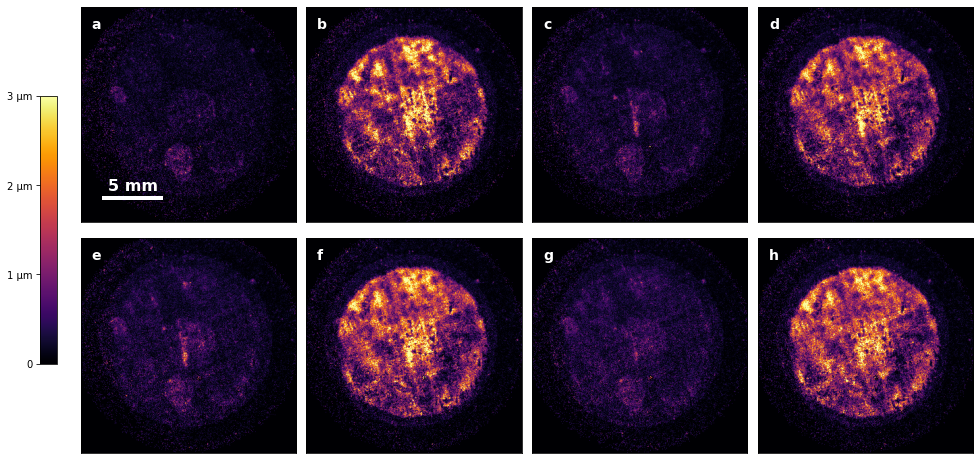

In [27]:
# === Capacity event images ===
from datetime import timedelta
import importlib.util
import os

pixel_size = 55
show_labels = True
label_start = 0  # used by potential-plot labeling

# Color bar
cmap = "inferno"
cbar_ranges = [(0, 3)]
cbar_length_frac = 0.8
cbar_mode = "shared right"
cbar_fontsize = 16
cbar_unit = ["μm"]
# cbar_width_frac = 0.01
cbar_show_ticklines = True

# Scale bar
scale_fontsize = 16
scalebar_mode = "outside left"
scalebar_length = 5000
scale_label = "5 mm"
scalebar_width_frac = 0.5

# Figure layout
spacing = (0.05, 0)
figsize = (16, 4)
ncols = 4
nrows = 2

# Defaults so downstream cells never fail
events = []
img_indices = []
event_times = []
event_times_for_plot = []

# Restrict capacity to image time range
if len(img_datetimes) == 0:
    raise ValueError("No image timestamps found. Check corrected image metadata.")

img_start = min(img_datetimes)
img_end = max(img_datetimes)

cap_times = []
cap_values = []
for t, c in zip(echem_datetimes, echem_thickness_series / conv_thickness):
    if img_start <= t <= img_end:
        cap_times.append(t)
        cap_values.append(c)

if len(cap_times) == 0:
    print("No capacity data within image time range.")
else:
    # Capacity events (turning points + zeros)
    events = operando_data.find_capacity_turning_points_and_zeros(
        cap_times,
        capacity_series=cap_values,
        only_initial_zero=True,
    )

if not events:
    print("No capacity events found.")
else:
    event_times = [e["time"] for e in events]
    img_indices = operando_data.find_nearest_image_indices(event_times, img_datetimes)

    # Use plotted-image timestamps for potential labels, shifted by -1 minute
    event_times_for_plot = [img_datetimes[idx] - timedelta(minutes=1) for idx in img_indices]

    for e, idx in zip(events, img_indices):
        print("{} {} -> image index {}".format(e["time"], e["labels"], idx))

    # Plot images at these indices
    plots_path = os.path.join(os.path.dirname(notebook_dir), "plots", "plots.py")
    plots_spec = importlib.util.spec_from_file_location("plots_mod", plots_path)
    plots_mod = importlib.util.module_from_spec(plots_spec)
    plots_spec.loader.exec_module(plots_mod)

    fig, axes = plots_mod.plot_images(
        img_series=img_series,
        img_indices=img_indices,
        pixel_size=55,
        show_labels=True,

        # Color bar
        cmap="inferno",
        cbar_ranges=[(0, 3)],
        cbar_shared_length=0.6,
        cbar_mode="shared left",
        cbar_fontsize=16,
        cbar_unit=["μm"],
        cbar_width_frac=0.015,
        cbar_show_ticklines=True,
        cbar_n_ticks=4,
        cbar_pad=0.02,

        # Scale bar
        scale_fontsize=16,
        scalebar_mode="inside",
        scalebar_length=5000,
        scale_label="5 mm",
        scalebar_width_frac=0.02,

        # Figure layout
        spacing=(0.05, 0),
        figsize=(16, 8.5),
        ncols=4,
        nrows=2,
    )

    # Save figure safely
    out_path = os.path.join(base_dir, "LiMetal", "nci_exp1301_LiMetal_final.png")
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved: {out_path}")


In [21]:
print(event_times)

[datetime.datetime(2025, 12, 10, 0, 40, 38), datetime.datetime(2025, 12, 10, 1, 40, 38), datetime.datetime(2025, 12, 10, 1, 40, 38), datetime.datetime(2025, 12, 10, 2, 36, 28), datetime.datetime(2025, 12, 10, 2, 36, 33), datetime.datetime(2025, 12, 10, 2, 36, 33), datetime.datetime(2025, 12, 10, 2, 36, 43), datetime.datetime(2025, 12, 10, 3, 36, 23), datetime.datetime(2025, 12, 10, 3, 36, 33), datetime.datetime(2025, 12, 10, 3, 36, 33), datetime.datetime(2025, 12, 10, 3, 36, 43), datetime.datetime(2025, 12, 10, 4, 33, 21), datetime.datetime(2025, 12, 10, 5, 38, 31), datetime.datetime(2025, 12, 10, 5, 38, 31), datetime.datetime(2025, 12, 10, 6, 36, 54), datetime.datetime(2025, 12, 10, 6, 36, 54), datetime.datetime(2025, 12, 10, 7, 36, 54), datetime.datetime(2025, 12, 10, 7, 36, 54)]


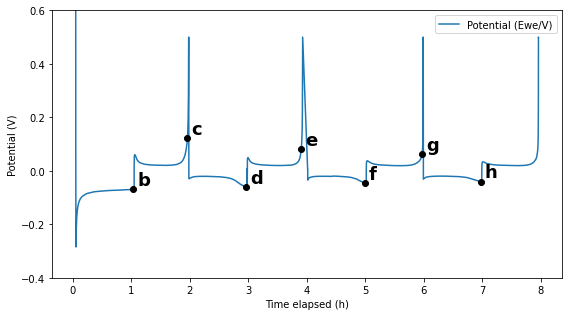

Saved: /data01/Leon_BOA_December2025/LiMetal/potential_exp1301_LiMetal_final.png


<Figure size 432x288 with 0 Axes>

In [29]:
# Make potential + thickness plot (image-derived thickness)
import os
import matplotlib.pyplot as plt
from datetime import timedelta

avg_thickness_series = operando_plots.circular_average_thickness_series(
    img_series, **roi
)

# Optional event labels (prefer timestamps prepared in capacity-event cell)
event_times_for_plot = globals().get("event_times_for_plot", None)
if event_times_for_plot is None:
    img_indices_local = globals().get("img_indices", [])
    event_times_for_plot = [img_datetimes[idx] - timedelta(minutes=1) for idx in img_indices_local]

label_start = globals().get("label_start", 0)

operando_plots.plot_potential_and_thickness(
    echem_datetime_series=echem_datetimes,
    potential_series=potential_series,
    echem_thickness_series=echem_thickness_series,
    img_datetime_series=img_datetimes,
    avg_thickness_series=avg_thickness_series,
    potential_ylim=potential_ylim,
    event_times=event_times_for_plot,
    label_start=label_start,
    event_marker_size=6,      # customize dot size
    event_label_fontsize=18,  # customize text size
)

# Save figure safely
fig = plt.gcf()
out_path = os.path.join(base_dir, "LiMetal", "potential_exp1301_LiMetal_final.png")
os.makedirs(os.path.dirname(out_path), exist_ok=True)
fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"Saved: {out_path}")
